# 1-1 함수 플로터

**오늘의 질문:** 센서 raw 값(0~4095)을 mm로 바꾸는 식 $y = ax + b$에서 $a$와 $b$는 무슨 뜻일까?

셀을 위에서부터 하나씩 실행한다 (Shift+Enter). 결과가 나오면 채팅에 적은 예측과 비교해 보자.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## 1. 자로 잰 두 점

물체를 150mm에 두었더니 raw = 1000, 350mm에 두었더니 raw = 3000이 나왔다.
가로축은 입력(raw), 세로축은 출력(mm)이다. 이렇게 가로축과 세로축으로 위치를 나타내는 판을 **좌표평면**이라고 한다.

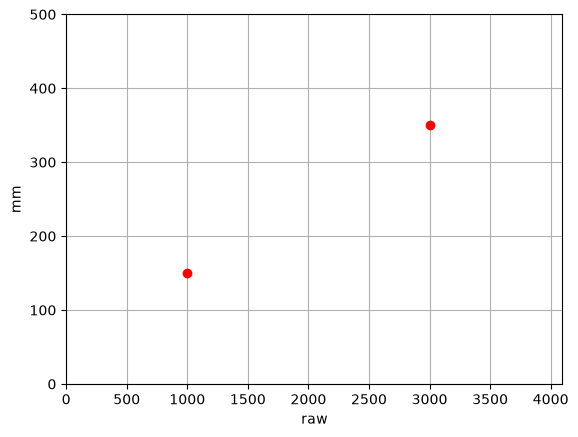

In [2]:
raw = np.array([1000, 3000])  # 센서가 보낸 숫자 (입력 x)
mm = np.array([150, 350])  # 자로 잰 실제 거리 (출력 y)

plt.scatter(raw, mm, color='red', zorder=3)
plt.xlim(0, 4095)
plt.ylim(0, 500)
plt.xlabel('raw')
plt.ylabel('mm')
plt.grid(True)
plt.show()

## 2. 두 점을 지나는 직선 — 일단 numpy에게 맡기기

`np.polyfit`은 점들을 지나는 직선 $y = ax + b$의 $a$와 $b$를 구해 준다. 어떻게 구하는지는 이론 시간에 직접 유도하고, 직접 짜 볼 거다. 지금은 결과만 본다.

In [3]:
a, b = np.polyfit(raw, mm, 1)  # 1 = 일차식, 즉 직선
print(f'a = {a:.4f}')
print(f'b = {b:.4f}')

a = 0.1000
b = 50.0000


In [4]:
def to_mm(r):
    return a * r + b


for r in [2000, 0, 4095]:
    print(f'raw {r:>4} → {to_mm(r):6.1f} mm')

raw 2000 →  250.0 mm
raw    0 →   50.0 mm
raw 4095 →  459.5 mm


예측과 같았나? 특히 raw = 0일 때를 보자. 그래프로 그리면 왜 그런지 보인다.

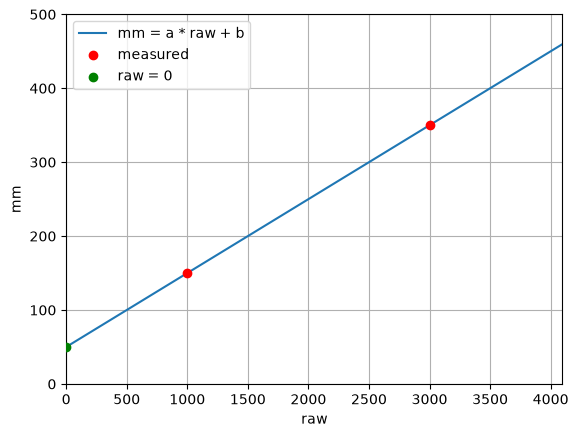

In [5]:
r = np.arange(0, 4096)  # 센서가 보낼 수 있는 모든 raw 값

plt.plot(r, to_mm(r), label='mm = a * raw + b')
plt.scatter(raw, mm, color='red', zorder=3, label='measured')
plt.scatter([0], [to_mm(0)], color='green', zorder=3, label='raw = 0')
plt.xlim(0, 4095)
plt.ylim(0, 500)
plt.xlabel('raw')
plt.ylabel('mm')
plt.legend()
plt.grid(True)
plt.show()

## 3. a와 b를 바꿔 보면?

왼쪽은 $b$를 50으로 두고 $a$만 바꾼 것, 오른쪽은 $a$를 0.1로 두고 $b$만 바꾼 것이다. 각각 그래프의 무엇이 바뀌나?

직접 바꿔 보기: 왼쪽 목록에 `-0.05`를 넣으면 어떻게 될까? 예측하고 나서 실행해 보자.

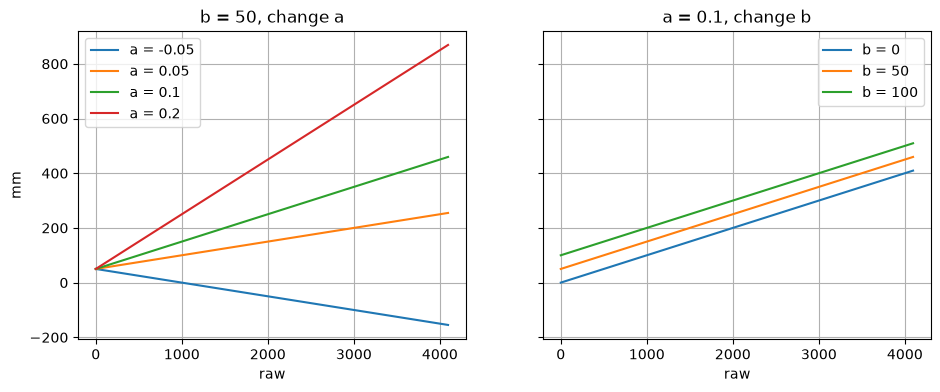

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for a_try in [-0.05, 0.05, 0.1, 0.2]:
    left.plot(r, a_try * r + 50, label=f'a = {a_try}')
left.set_title('b = 50, change a')

for b_try in [0, 50, 100]:
    right.plot(r, 0.1 * r + b_try, label=f'b = {b_try}')
right.set_title('a = 0.1, change b')

for ax in (left, right):
    ax.set_xlabel('raw')
    ax.legend()
    ax.grid(True)
left.set_ylabel('mm')
plt.show()

In [8]:
# raw가 1 늘면 mm는 얼마나 늘까? 어디서 재든 같을까?
print(f'{to_mm(1001) - to_mm(1000):.4f}')
print(f'{to_mm(2501) - to_mm(2500):.4f}')
print(f'{to_mm(4001) - to_mm(4000):.4f}')

0.1000
0.1000
0.1000


## 4. 넣어도 되는 값, 나올 수 있는 값

센서는 0부터 4095까지의 정수만 보낸다. 함수에 넣어도 되는 값의 모음을 **정의역**, 그 결과로 나올 수 있는 값의 모음을 **치역**이라고 한다. 코드로 치면 정의역은 입력 검증, 치역은 반환값의 범위다.

In [9]:
def to_mm_checked(r):
    if not 0 <= r <= 4095:
        raise ValueError(f'센서는 0~4095만 보낸다: {r}')
    return a * r + b


print(f'가장 가까운 거리: {to_mm_checked(0):.1f} mm')
print(f'가장 먼 거리: {to_mm_checked(4095):.1f} mm')

try:
    to_mm_checked(5000)
except ValueError as e:
    print('에러:', e)

가장 가까운 거리: 50.0 mm
가장 먼 거리: 459.5 mm
에러: 센서는 0~4095만 보낸다: 5000
